In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in oamb_ko_analysis.py next to this notebook
# (run it as a script to regenerate everything: python oamb_ko_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import oamb_ko_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,closed_loop,dark,usable,notes,session,fly_id
0,18_08_2026,fly1,closed_loop-000,0,fictrac-20260818_105847.dat,het,closed_loop,1,0,1,NaN,closed_loop-000,18_08_2026_fly1_condition_het
1,18_08_2026,fly1,dark-001,1,fictrac-20260818_105847.dat,het,dark,0,1,1,NaN,dark-001,18_08_2026_fly1_condition_het
2,18_08_2026,fly2,closed_loop-000,0,fictrac-20260818_114333.dat,het,closed_loop,1,0,1,NaN,closed_loop-000,18_08_2026_fly2_condition_het
3,18_08_2026,fly2,dark-001,1,fictrac-20260818_114333.dat,het,dark,0,1,1,NaN,dark-001,18_08_2026_fly2_condition_het
4,18_08_2026,fly1,closed_loop-000,0,fictrac-20260818_093924.dat,ko,closed_loop,1,0,1,NaN,closed_loop-000,18_08_2026_fly1_condition_ko


## Offset vector length and variance, dark vs closed loop

offset_var_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,15.887011,1,17,15.887011,25.875724,0.000091,0.603505,NaN
1,dark,18.312722,1,17,18.312722,24.321626,0.000126,0.588593,1.0
2,Interaction,4.314015,1,17,4.314015,5.729561,0.028490,0.252075,NaN


offset_var_pairwise_dark_effect


,Contrast,condition,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,condition,-,het,ko,False,True,-5.157843,16.671433,two-sided,0.000084,NaN,NaN,238.44,-2.232580
1,dark,-,0,1,True,True,-4.388711,18.000000,two-sided,0.000354,NaN,NaN,91.557,-1.237429
2,condition * dark,het,0,1,True,True,-7.400672,9.000000,two-sided,0.000041,0.000082,holm,612.545,-2.582336
3,condition * dark,ko,0,1,True,True,-1.325440,8.000000,two-sided,0.221625,0.221625,holm,0.634,-0.714857


offset_var_pairwise_group_effect


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-4.388711,18.000000,two-sided,0.000354,NaN,NaN,91.557,-1.237429
1,condition,-,het,ko,False,True,-5.157843,16.671433,two-sided,0.000084,NaN,NaN,238.44,-2.232580
2,dark * condition,0,het,ko,False,True,-5.344204,16.999891,two-sided,0.000054,0.000107,holm,329.974,-2.331397
3,dark * condition,1,het,ko,False,True,-1.557186,13.181706,two-sided,0.143103,0.143103,holm,0.915,-0.700309


offset_n_flies


,condition,n_flies
0,het,10
1,ko,9


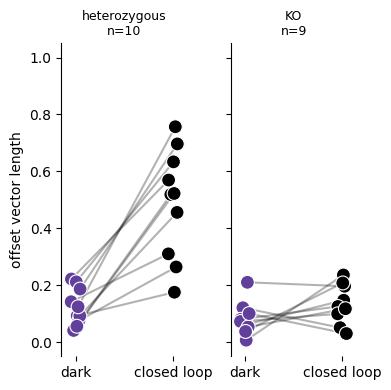

In [4]:
offset_unique, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PV magnitude vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/group_comparison.py:175: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


rho_mean_over_speed_tests


,condition,test,comparison,statistic,p,p_holm
0,closed loop,Mann-Whitney U,heterozygous vs KO,87.0,0.000703,0.000703
1,dark,Mann-Whitney U,heterozygous vs KO,63.0,0.153042,0.153042


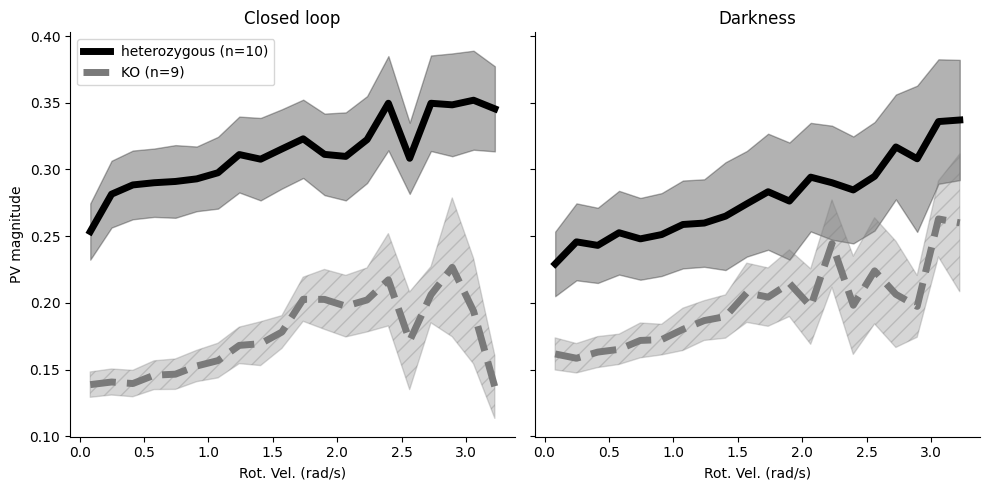

In [5]:
rho_grouped, rho_tables = ana.rho_analysis(sess_manager)
for name, table in rho_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PVA velocity vs rotation speed

dphi_ols_closed_loop
                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.068
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     9.185
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           7.05e-06
Time:                        15:50:15   Log-Likelihood:                -424.81
No. Observations:                 380   AIC:                             857.6
Df Residuals:                     376   BIC:                             873.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

,condition,terms,F,p
0,closed_loop,slope differences (dh:group),18.737478,0.000019
1,closed_loop,intercept differences (group),1.924384,0.166196
2,dark,slope differences (dh:group),2.960622,0.086138
3,dark,intercept differences (group),2.802696,0.094938


dphi_coefficients


,condition,term,coef,p,p_holm
0,closed_loop,"dh:C(condition, Treatment(""het""))[T.ko]",-0.545120,0.000019,0.000019
1,dark,"dh:C(condition, Treatment(""het""))[T.ko]",-0.227262,0.086138,0.086138


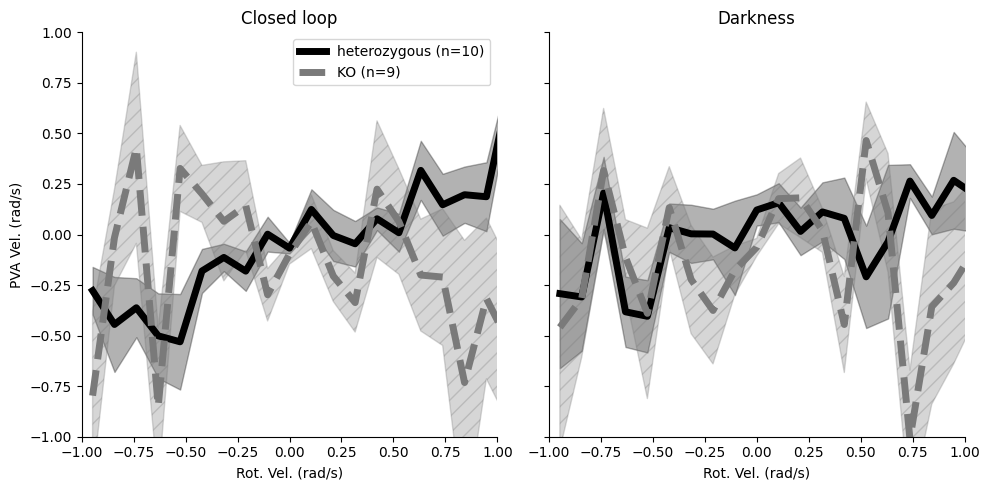

In [6]:
dphi_grouped, dphi_tables = ana.dphi_analysis(sess_manager)
for name, table in dphi_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Bump width

bump_width_tests


,family,comparison,n,W,p,p_holm
0,closed loop vs dark,heterozygous,10.0,2.0,0.005859,0.011719
1,closed loop vs dark,KO,9.0,7.0,0.074219,0.074219
2,"closed loop, between groups",heterozygous vs KO,NaN,2.0,0.000520,0.000520


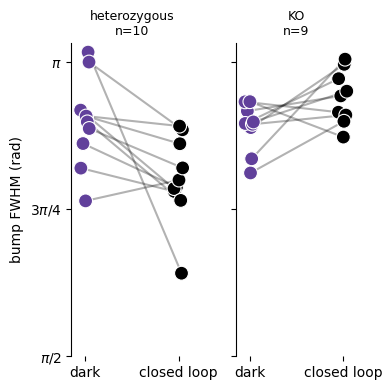

In [8]:
widths, width_tables = ana.width_analysis(sess_manager)
for name, table in width_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Closed-loop and dark heatmaps of every fly

In [9]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

19